# HuggingFace pipelines

For this session we head to Google Colab and use this Notebook to explore the HuggingFace High Level API, pipelines.

https://colab.research.google.com/drive/1aMaEw8A56xs0bRM4lu8z7ou18jqyybGm?usp=sharing

You can use a low cost (or free) T4 GPU runtime for this notebook - and the results look great!

There are instructions in the notebook for setting up your HuggingFace Token and including it as a secret in the notebook.

In [19]:
# Imports

import torch
from huggingface_hub import login
from transformers import pipeline
from diffusers import DiffusionPipeline
from datasets import load_dataset
import soundfile as sf
from IPython.display import Audio
import dotenv, os

In [20]:
# Loading .env file and the required token:
dotenv.load_dotenv()
hf_token = os.environ.get('HUGGING_FACE')

In [3]:
# Sentiment Analysis

my_simple_sentiment_analyzer = pipeline("sentiment-analysis", device="cuda", token=hf_token)
result = my_simple_sentiment_analyzer("I'm super excited to be on the way to LLM mastery!")
print(result)

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9993460774421692}]


In [4]:
result = my_simple_sentiment_analyzer("I should be more excited to be on the way to LLM mastery!")
print(result)

[{'label': 'POSITIVE', 'score': 0.9008281230926514}]


In [5]:
better_sentiment = pipeline("sentiment-analysis", model="nlptown/bert-base-multilingual-uncased-sentiment", device="cuda")
result = better_sentiment("I should be more excited to be on the way to LLM mastery!!")
print(result)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'label': '3 stars', 'score': 0.39448001980781555}]


In [6]:
text_pipeline  = pipeline('text-to-speech',model='microsoft/speecht5_tts',device="cuda", token= hf_token)

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

[transformers] SpeechT5ForTextToSpeech LOAD REPORT from: microsoft/speecht5_tts
Key                                         | Status     |  | 
--------------------------------------------+------------+--+-
speecht5.encoder.prenet.encode_positions.pe | UNEXPECTED |  | 
speecht5.decoder.prenet.encode_positions.pe | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] You are using a model of type `hifigan` to instantiate a model of type `speecht5_hifigan`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/158 [00:00<?, ?it/s]

In [7]:
from transformers import pipeline
from PIL import Image

detector = pipeline(model="facebook/detr-resnet-50", token = hf_token)
detector("https://huggingface.co/datasets/Narsil/image_dummy/raw/main/parrots.png")

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'score': 0.9966109395027161,
  'label': 'bird',
  'box': {'xmin': 69, 'ymin': 171, 'xmax': 396, 'ymax': 507}},
 {'score': 0.9993813037872314,
  'label': 'bird',
  'box': {'xmin': 398, 'ymin': 105, 'xmax': 767, 'ymax': 507}}]

In [8]:
image = Image.open("C:/Users/teede/Downloads/IMG_0029.JPG")

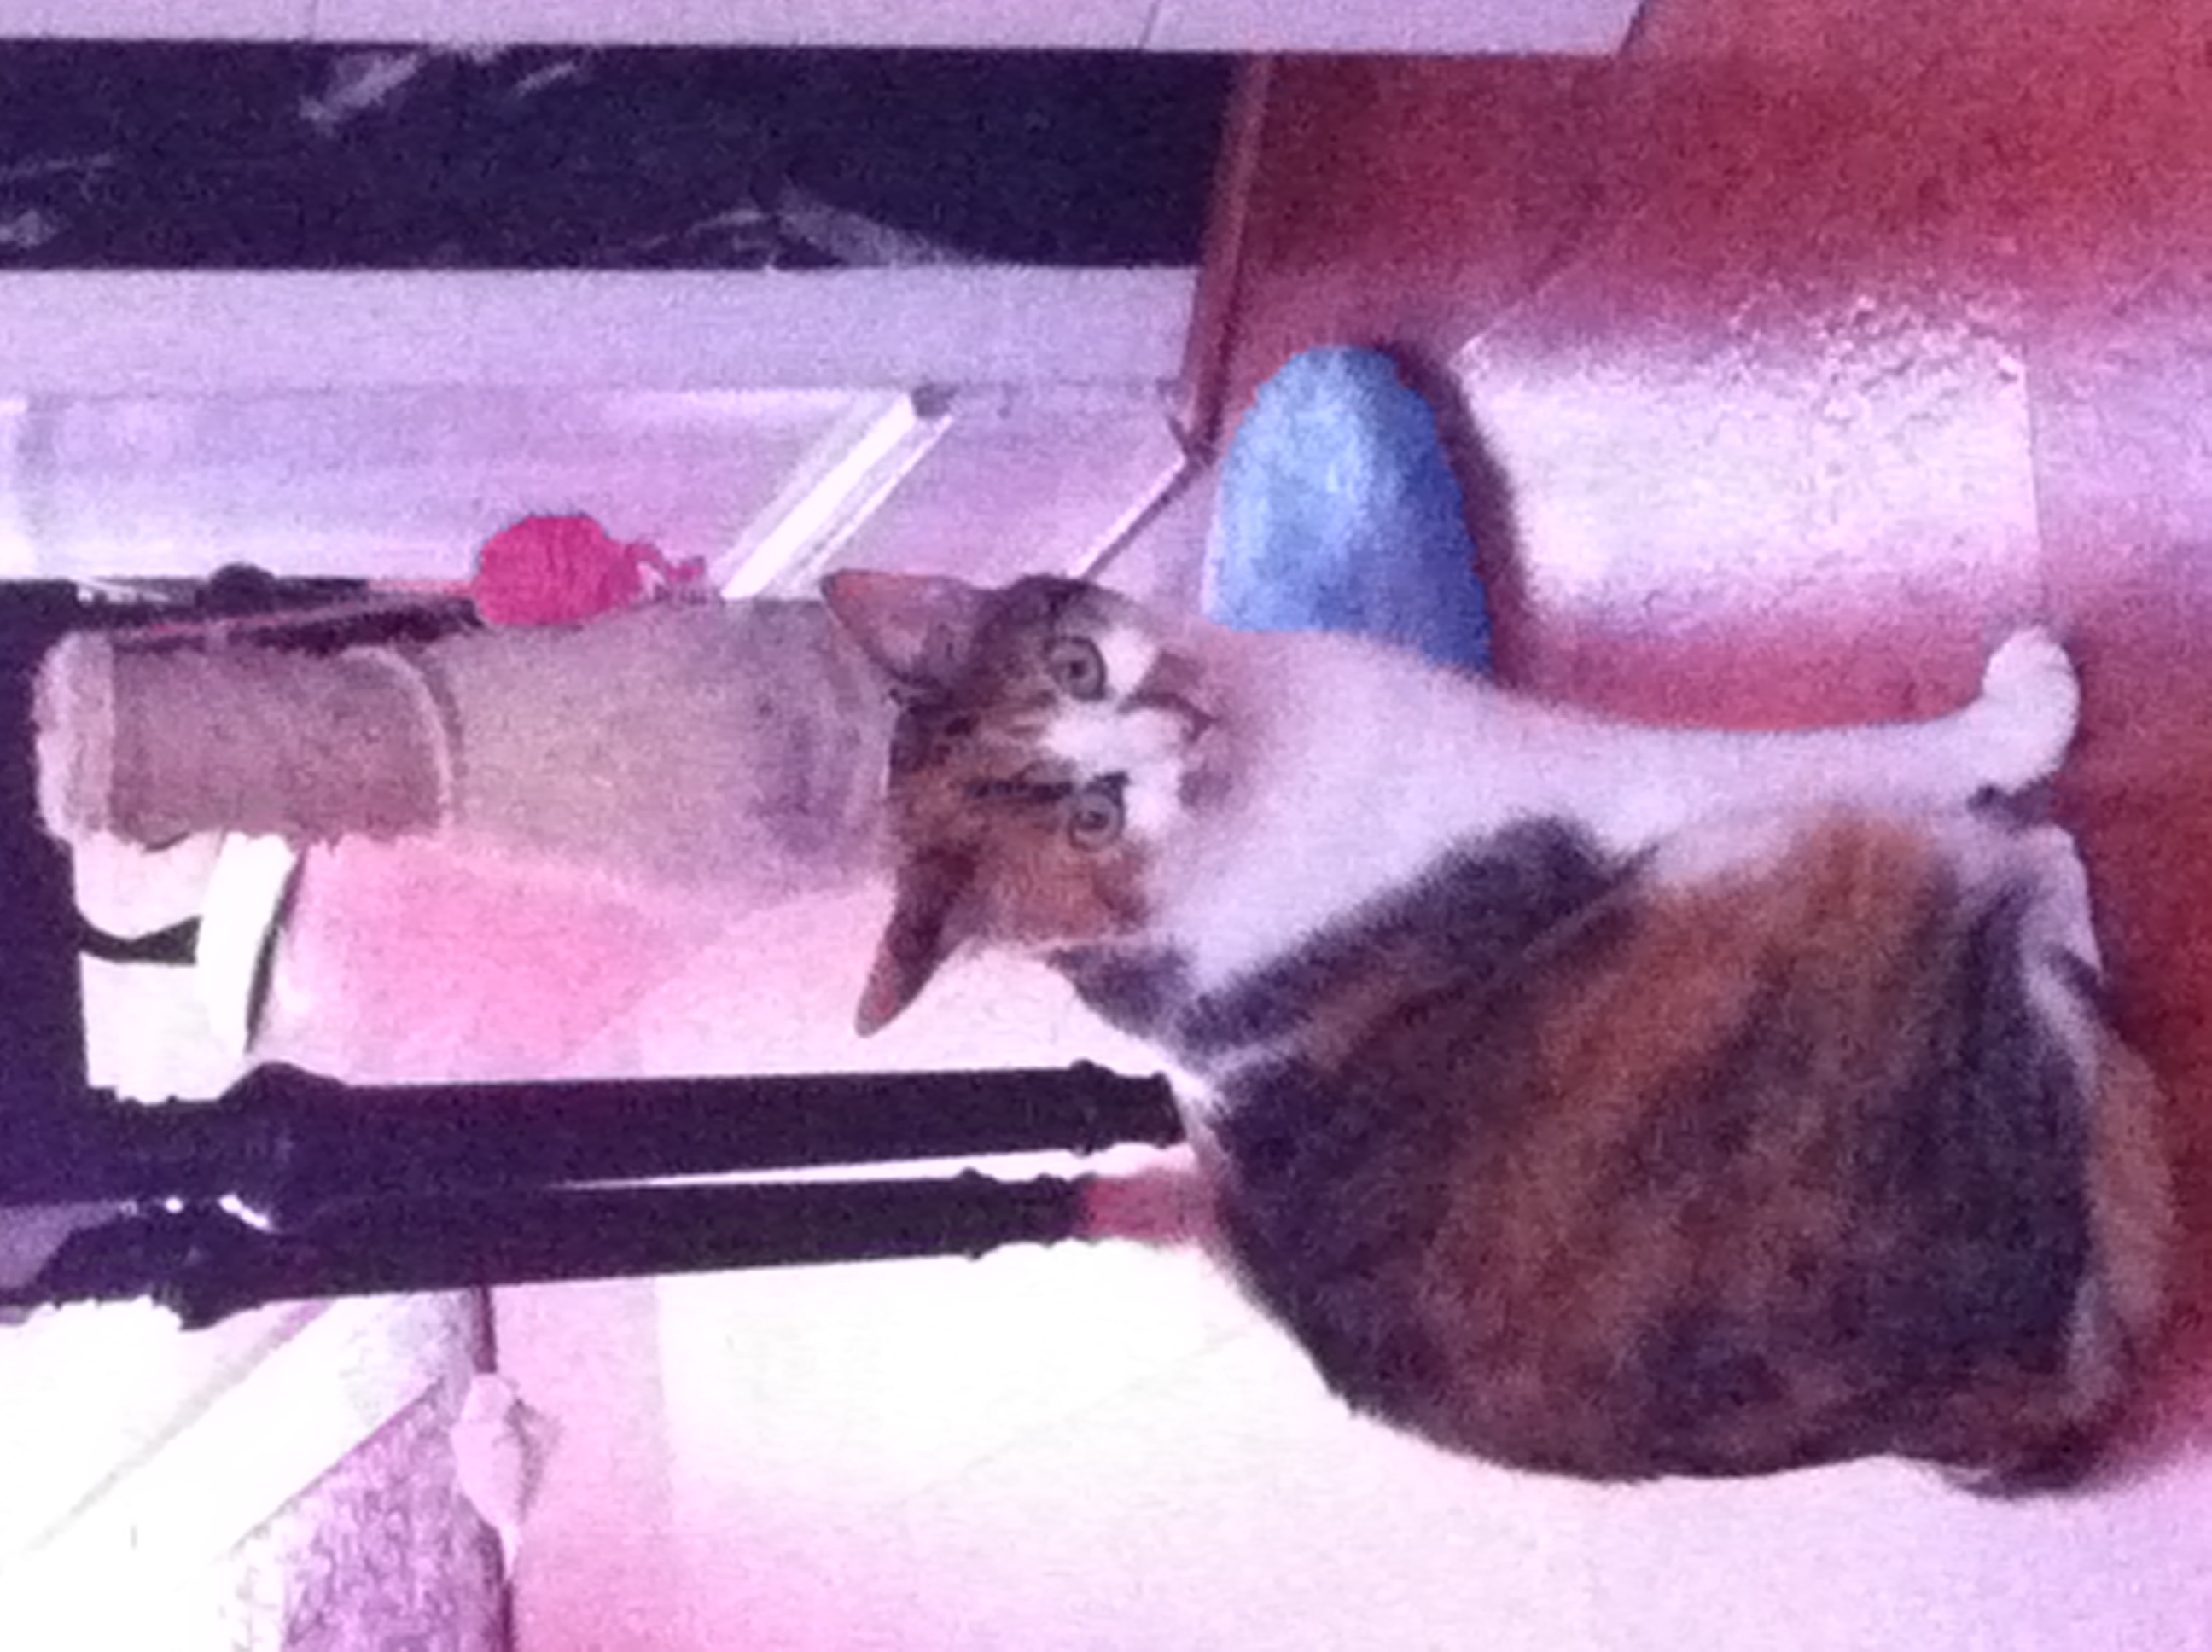

In [9]:
image

In [10]:
detector(image)

[{'score': 0.9974416494369507,
  'label': 'cat',
  'box': {'xmin': 178, 'ymin': 953, 'xmax': 1276, 'ymax': 2526}}]

In [11]:
# NER: Named entity recognition

ner = pipeline('ner',device = 'cuda', token = hf_token)


[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [12]:
for item in ner('I would like to buy a website for a bed and breakfast in France. In order to do so, I want to use Django'):
    print(item)

{'entity': 'I-LOC', 'score': np.float32(0.99984705), 'index': 14, 'word': 'France', 'start': 57, 'end': 63}
{'entity': 'I-MISC', 'score': np.float32(0.9400174), 'index': 26, 'word': 'D', 'start': 98, 'end': 99}
{'entity': 'I-MISC', 'score': np.float32(0.43408164), 'index': 27, 'word': '##jan', 'start': 99, 'end': 102}
{'entity': 'I-MISC', 'score': np.float32(0.7798294), 'index': 28, 'word': '##go', 'start': 102, 'end': 104}


In [17]:
# Using NER to find the correct context, interesting thought! I would store the context in a dictionary or sql DB. 
question = 'can you tell me something about petit-soleil?'
context = 'petit-soleil is a bed and breakfast in France.'
question_answering = pipeline(model = "meta-llama/Llama-3.1-8B-Instruct", device_map='cuda', token=hf_token)

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

c:\Users\teede\projects\llm_engineering\.venv\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\teede\.cache\huggingface\hub\models--meta-llama--Llama-3.1-8B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

In [18]:
prompt = [{
    "role":"system",
    "content":"You're a helpful assistant. Try to help the user to your best of your abilities. A bit of context: petit-soleil is a bed and breakfast in France."
},{
    "role":"user",
    "content": "can you tell me something about petit-soleil?"
}]

question_answering(prompt)

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': [{'role': 'system',
    'content': "You're a helpful assistant. Try to help the user to your best of your abilities. A bit of context: petit-soleil is a bed and breakfast in France."},
   {'role': 'user',
    'content': 'can you tell me something about petit-soleil?'},
   {'role': 'assistant',
    'content': "Petit-Soleil sounds like a charming place. Unfortunately, I don't have any specific information about a bed and breakfast with that name in France. \n\nHowever, I can suggest some possibilities: \n\n1. Petit-Soleil could be a small, family-run B&B, and it might not have a strong online presence. \n2. It's possible that Petit-Soleil is a lesser-known or off-the-beaten-path destination in France.\n3. Petit-Soleil might be a fictional or hypothetical place, and you could be thinking of a different name.\n\nIf you have more information about Petit-Soleil, such as its location or any other details you remember, I'd be happy to try and help you further."}]}]

In [21]:
translator = pipeline("translation_en_to_fr", device="cuda", token=hf_token)
result = translator("The Data Scientists were truly amazed by the power and simplicity of the HuggingFace pipeline API.")
print(result[0]['translation_text'])

KeyError: "Unknown task translation_en_to_fr, available tasks are ['any-to-any', 'audio-classification', 'automatic-speech-recognition', 'depth-estimation', 'document-question-answering', 'feature-extraction', 'fill-mask', 'image-classification', 'image-feature-extraction', 'image-segmentation', 'image-text-to-text', 'keypoint-matching', 'mask-generation', 'ner', 'object-detection', 'sentiment-analysis', 'table-question-answering', 'text-classification', 'text-generation', 'text-to-audio', 'text-to-speech', 'token-classification', 'video-classification', 'zero-shot-audio-classification', 'zero-shot-classification', 'zero-shot-image-classification', 'zero-shot-object-detection']"